# 03 — EDA · VISUALIZACIONES

In [1]:
# ============================================================
# 03 — EDA · VISUALIZACIONES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración visual
sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Carga del dataset limpio
ruta = Path("../../data/processed/suicidio_limpio.csv")
df = pd.read_csv(ruta)

# Dataset consolidado:
# evita contar varias veces la misma combinación país-año
df_both = df[df["sex"] == "both"].copy()

print("Dataset cargado correctamente.")
print(f"Filas dataset completo: {df.shape[0]:,}")
print(f"Filas consolidadas: {df_both.shape[0]:,}")

df.head()

Dataset cargado correctamente.
Filas dataset completo: 18,018
Filas consolidadas: 6,006


,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.36,3.521418e+09,174.930991,20130327
1,Afghanistan,AFG,2000,female,all_ages,2.91,3.521418e+09,174.930991,20130327
2,Afghanistan,AFG,2000,male,all_ages,5.79,3.521418e+09,174.930991,20130327
3,Afghanistan,AFG,2001,both,all_ages,4.38,2.813572e+09,138.706822,20284307
4,Afghanistan,AFG,2001,female,all_ages,2.92,2.813572e+09,138.706822,20284307


## Distribución de la tasa de suicidio

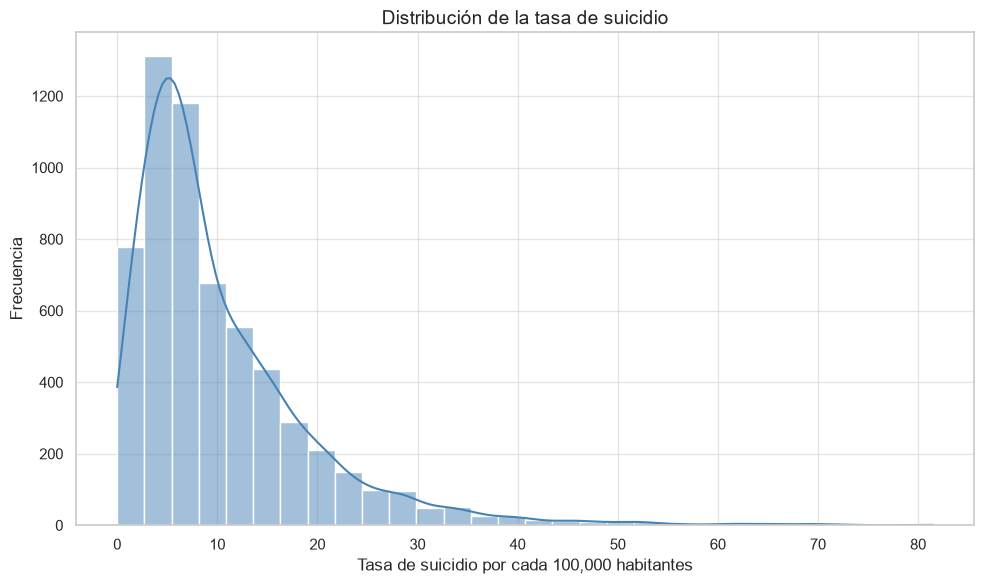

In [2]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_both,
    x="suicide_rate_per_100k",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribución de la tasa de suicidio")
plt.xlabel("Tasa de suicidio por cada 100,000 habitantes")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

El histograma muestra que la mayor concentración de observaciones se encuentra en tasas relativamente bajas, con un pico aproximadamente entre 5 y 7 suicidios por cada 100,000 habitantes. A partir de este punto, la frecuencia disminuye progresivamente conforme aumenta la tasa.

La distribución presenta una asimetría positiva o hacia la derecha, con una cola prolongada que incluye algunos registros con tasas superiores a 40, 50 e incluso 80 por cada 100,000 habitantes. Esto indica que la mayoría de los países-año presentan tasas considerablemente menores, mientras que existe un grupo reducido con tasas excepcionalmente altas.

Esta forma de la distribución también permite anticipar la presencia de valores atípicos superiores, los cuales se analizan con mayor claridad mediante el boxplot. Estos valores no deben considerarse automáticamente errores, ya que pueden corresponder a observaciones reales de determinados países y períodos.

## Boxplot y valores atípicos

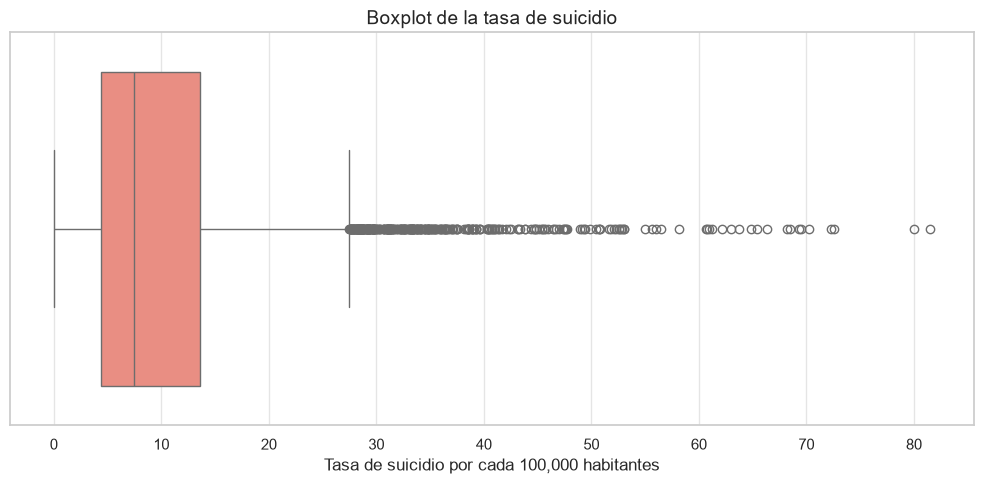

In [3]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_both,
    x="suicide_rate_per_100k",
    color="salmon"
)

plt.title("Boxplot de la tasa de suicidio")
plt.xlabel("Tasa de suicidio por cada 100,000 habitantes")

plt.tight_layout()
plt.show()

El boxplot confirma la asimetría positiva observada anteriormente en el histograma. La mayor parte de las tasas se concentra aproximadamente entre 5 y 14 suicidios por cada 100,000 habitantes, con una mediana cercana a 7–8. Esto indica que la mitad central de las observaciones se encuentra principalmente en valores relativamente bajos y moderados.

A partir de aproximadamente 27–28 suicidios por cada 100,000 habitantes aparecen numerosos valores atípicos, algunos superiores a 50 y casos extremos que alcanzan aproximadamente 80–82. Estos valores explican la larga cola derecha observada en el histograma y muestran que existe un grupo reducido de países-año con tasas considerablemente superiores al comportamiento general.

Es importante destacar que un valor atípico no implica necesariamente un error en los datos. En este contexto, puede representar una observación real correspondiente a un país y período con una tasa excepcionalmente alta. Por ello, estos registros deben identificarse y analizarse antes de decidir si requieren algún tratamiento en etapas posteriores.

In [14]:
# Observaciones con las tasas más altas
df_both.nlargest(
    10,
    "suicide_rate_per_100k"
)[
    ["country", "year", "suicide_rate_per_100k"]
]

,country,year,suicide_rate_per_100k
11181,Mozambique,2021,81.51
9684,Lesotho,2021,79.96
9687,Lesotho,2021,72.56
2766,Central African Republic,2021,72.26
1083,Burundi,2021,70.22
3459,"Congo, The Democratic Republic of the",2021,69.45
14151,Senegal,2021,69.32
1380,Burkina Faso,2021,68.49
11478,Malawi,2021,68.22
13854,Rwanda,2021,66.36


El boxplot confirma la presencia de numerosos valores atípicos superiores y la fuerte asimetría positiva observada previamente en el histograma. La mayoría de las observaciones se concentra en tasas considerablemente menores, mientras que existe un grupo reducido de registros con tasas muy elevadas.

Al analizar específicamente los valores más extremos, Mozambique presenta la tasa más alta, con 81.51 suicidios por cada 100,000 habitantes en 2021, seguido por Lesotho con 79.96. También destacan Central African Republic (72.26), Burundi (70.22) y Congo, Democratic Republic of the (69.45).

Un hallazgo importante es que los diez registros con las tasas más altas corresponden al año 2021. Esto sugiere que los valores extremos no solo presentan un patrón geográfico, sino también una concentración temporal que debe considerarse en el análisis. Estos registros no se eliminan automáticamente, ya que un valor atípico puede representar una observación real y relevante, y no necesariamente un error.

In [18]:
df_both.nlargest(
    10,
    "suicide_rate_per_100k"
)[
    ["country", "year", "age_bracket", "suicide_rate_per_100k"]
]

,country,year,age_bracket,suicide_rate_per_100k
11181,Mozambique,2021,70plus,81.51
9684,Lesotho,2021,40-49,79.96
9687,Lesotho,2021,50-59,72.56
2766,Central African Republic,2021,70plus,72.26
1083,Burundi,2021,70plus,70.22
3459,"Congo, The Democratic Republic of the",2021,70plus,69.45
14151,Senegal,2021,70plus,69.32
1380,Burkina Faso,2021,70plus,68.49
11478,Malawi,2021,70plus,68.22
13854,Rwanda,2021,70plus,66.36


## Comparación según sexo

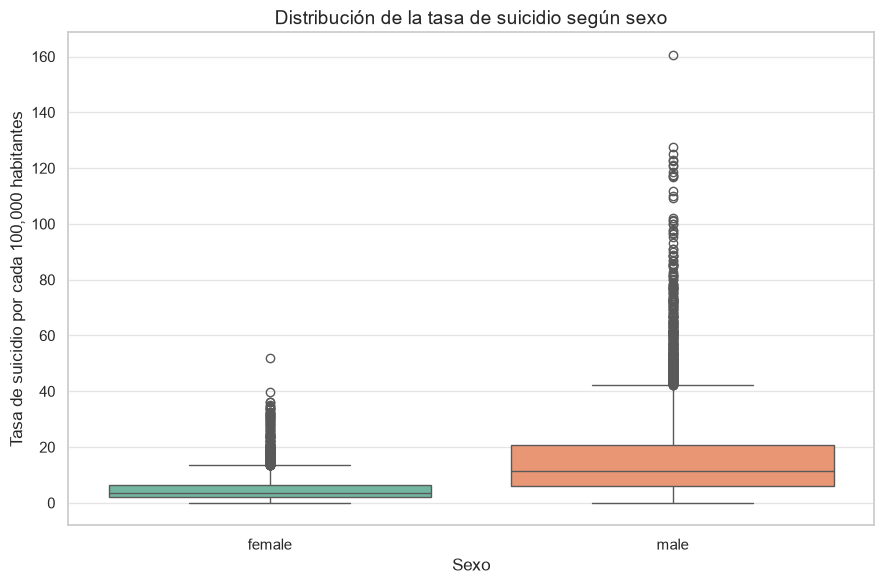

In [4]:
df_sex = df[df["sex"].isin(["male", "female"])].copy()

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_sex,
    x="sex",
    y="suicide_rate_per_100k",
    hue="sex",
    legend=False,
    palette="Set2"
)

plt.title("Distribución de la tasa de suicidio según sexo")
plt.xlabel("Sexo")
plt.ylabel("Tasa de suicidio por cada 100,000 habitantes")

plt.tight_layout()
plt.show()

El boxplot muestra una diferencia clara entre las distribuciones de las tasas de suicidio según sexo. Las observaciones correspondientes a male presentan una mediana considerablemente superior, cercana a 11 suicidios por cada 100,000 habitantes, mientras que para female la mediana se encuentra aproximadamente entre 3 y 4.

Además, la distribución masculina presenta mayor dispersión. La mitad central de sus observaciones se encuentra aproximadamente entre 6 y 20 por cada 100,000 habitantes, mientras que las observaciones femeninas están mucho más concentradas en valores bajos, aproximadamente entre 2 y 6.

También se identifican valores atípicos en ambos grupos, aunque son mucho más numerosos y extremos en male. Mientras que en female los valores extremos alcanzan aproximadamente 50 por cada 100,000 habitantes, en male se observan tasas superiores a 100 y un caso extremo cercano a 160.

En conjunto, el gráfico muestra que las observaciones masculinas no solo presentan tasas de suicidio típicamente mayores, sino también una mayor variabilidad y valores extremos más elevados que las observaciones femeninas. Por tanto, el sexo presenta una asociación importante con las diferencias observadas en la tasa de suicidio dentro de este conjunto de datos.

In [19]:
df_sex.groupby("sex")["suicide_rate_per_100k"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
sex,,,,,,
female,6006,4.96,3.64,4.54,0.0,52.02
male,6006,15.88,11.25,15.20,0.0,160.59


## Evolución temporal

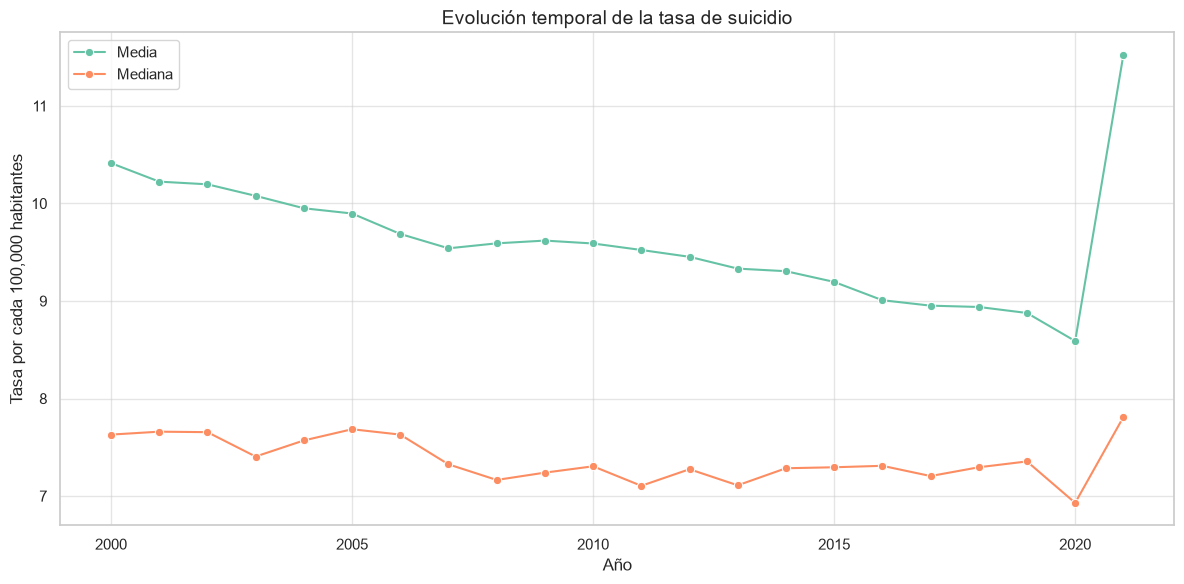

In [5]:
evolucion = (
    df_both.groupby("year")["suicide_rate_per_100k"]
    .agg(["mean", "median"])
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=evolucion,
    x="year",
    y="mean",
    marker="o",
    label="Media"
)

sns.lineplot(
    data=evolucion,
    x="year",
    y="median",
    marker="o",
    label="Mediana"
)

plt.title("Evolución temporal de la tasa de suicidio")
plt.xlabel("Año")
plt.ylabel("Tasa por cada 100,000 habitantes")

plt.legend()
plt.tight_layout()
plt.show()

Entre 2000 y 2020 se observa una tendencia general descendente en la media de la tasa de suicidio. La media pasa de aproximadamente 10.4 por cada 100,000 habitantes en 2000 a cerca de 8.6 en 2020, aunque existen pequeñas fluctuaciones durante el período.

La mediana presenta un comportamiento mucho más estable, manteniéndose aproximadamente entre 7.1 y 7.7 durante la mayor parte de los años. Además, la media se encuentra consistentemente por encima de la mediana, lo cual coincide con la asimetría positiva identificada anteriormente en el histograma y el boxplot: las observaciones con tasas elevadas desplazan la media hacia valores superiores.

Un comportamiento particularmente llamativo aparece en 2021, cuando la media aumenta abruptamente hasta aproximadamente 11.5, mientras que la mediana aumenta de aproximadamente 6.9 a 7.8. Debido a que el incremento de la media es mucho mayor que el de la mediana, el cambio parece estar influenciado principalmente por observaciones con tasas excepcionalmente altas, más que por un aumento uniforme en todos los registros.

Este patrón es consistente con los valores extremos identificados previamente para 2021. Por ello, 2021 debe interpretarse con precaución, considerando que el conjunto de datos conserva diferentes grupos de edad y que algunas observaciones específicas presentan tasas considerablemente elevadas.

## Países con las tasas promedio más altas

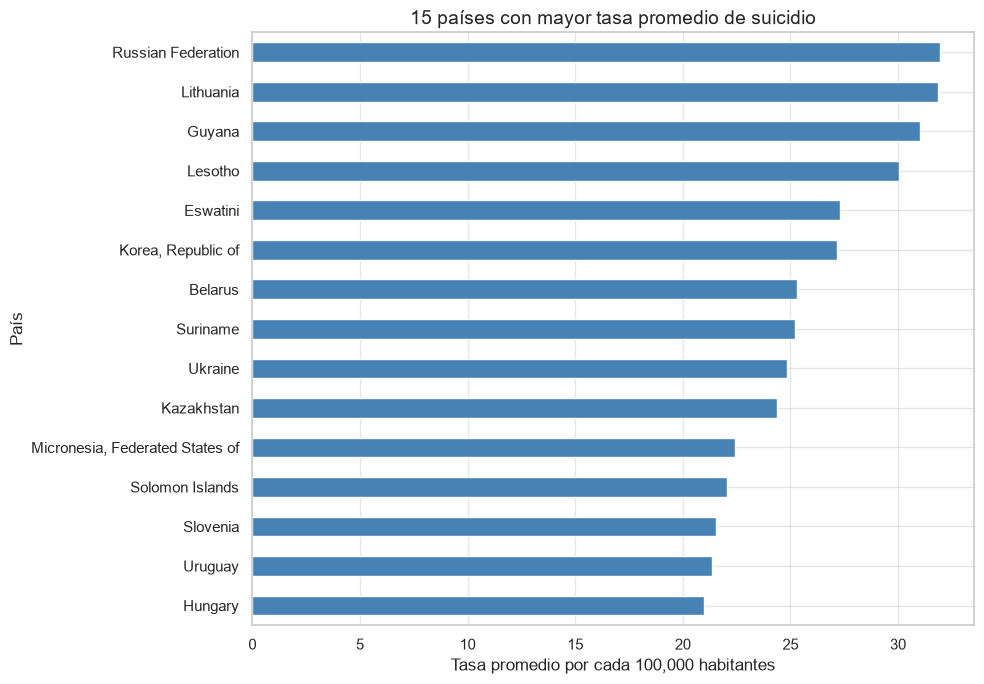

In [6]:
top_paises = (
    df_both.groupby("country")["suicide_rate_per_100k"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

top_paises.plot(
    kind="barh",
    color="steelblue"
)

plt.title("15 países con mayor tasa promedio de suicidio")
plt.xlabel("Tasa promedio por cada 100,000 habitantes")
plt.ylabel("País")

plt.tight_layout()
plt.show()

El gráfico compara la tasa promedio de las observaciones disponibles para cada país, considerando los registros correspondientes a ambos sexos (both) y manteniendo los diferentes años y grupos de edad presentes en el conjunto de datos.

Russian Federation y Lithuania presentan los promedios más elevados, cercanos a 32 suicidios por cada 100,000 habitantes, seguidas por Guyana, con aproximadamente 31, y Lesotho, con cerca de 30. También destacan Eswatini y Korea, Republic of, con valores cercanos a 27.

Los resultados evidencian una considerable variación entre países y muestran que las observaciones con tasas elevadas no se concentran exclusivamente en un único país o región. Sin embargo, estos valores representan promedios de las observaciones disponibles por país, por lo que no deben interpretarse como la tasa nacional de un año específico.

Además, debido a que el cálculo incluye diferentes años y grupos de edad, el promedio resume comportamientos que pueden variar considerablemente dentro de cada país. Por esta razón, el ranking debe interpretarse como una herramienta exploratoria para identificar países que presentan valores elevados en el conjunto de datos, y complementarse con el análisis temporal y por grupos.

## Matriz de correlación

In [7]:
variables_numericas = [
    "year",
    "suicide_rate_per_100k",
    "gdp_usd",
    "gdp_per_capita_usd",
    "total_country_population"
]

correlacion = df_both[variables_numericas].corr()

correlacion.round(2)

,year,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
year,1.00,0.05,0.07,0.14,0.02
suicide_rate_per_100k,0.05,1.00,0.07,0.07,0.02
gdp_usd,0.07,0.07,1.00,0.26,0.52
gdp_per_capita_usd,0.14,0.07,0.26,1.00,-0.04
total_country_population,0.02,0.02,0.52,-0.04,1.00


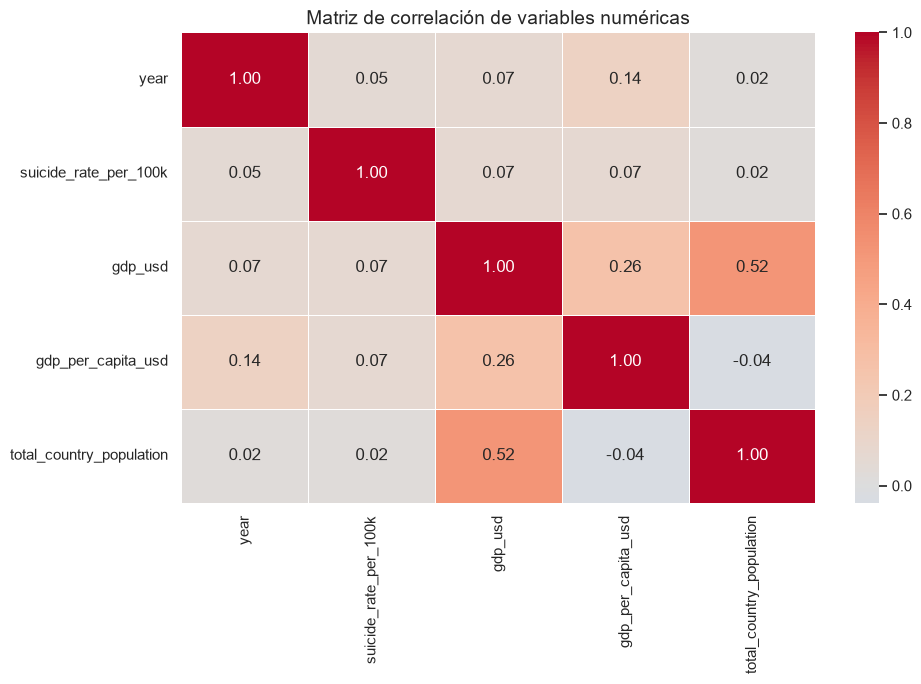

In [8]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación de variables numéricas")

plt.tight_layout()
plt.show()

La matriz de correlación muestra que la tasa de suicidio presenta relaciones lineales muy débiles con las demás variables numéricas analizadas. La correlación con year es de 0.05, con gdp_usd de 0.07, con gdp_per_capita_usd de 0.07 y con total_country_population de apenas 0.02. Estos valores, al encontrarse muy próximos a cero, indican que no existe una asociación lineal fuerte entre estas variables y la tasa de suicidio dentro del conjunto de datos.

La relación más destacada de toda la matriz se encuentra entre gdp_usd y total_country_population, con una correlación positiva de 0.52. Este valor representa una asociación moderada: en las observaciones analizadas, valores mayores de población tienden a estar asociados con valores mayores de PIB total.

También se observa una correlación positiva débil de 0.26 entre gdp_usd y gdp_per_capita_usd, mientras que gdp_per_capita_usd y total_country_population presentan una correlación prácticamente nula y ligeramente negativa de -0.04.

En conjunto, los resultados sugieren que la tasa de suicidio no presenta una relación lineal simple con el PIB, el PIB per cápita, la población o el año. Por lo tanto, las diferencias observadas en la tasa de suicidio probablemente requieren considerar múltiples características simultáneamente y posibles relaciones no lineales, aspecto relevante para las etapas posteriores del análisis.

## PIB per cápita vs. tasa de suicidio

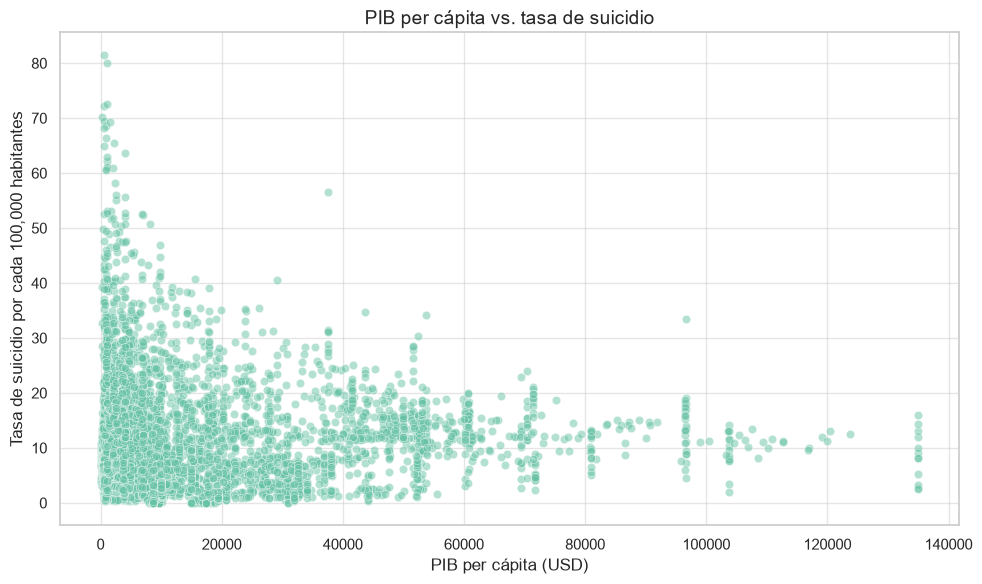

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_both,
    x="gdp_per_capita_usd",
    y="suicide_rate_per_100k",
    alpha=0.5
)

plt.title("PIB per cápita vs. tasa de suicidio")
plt.xlabel("PIB per cápita (USD)")
plt.ylabel("Tasa de suicidio por cada 100,000 habitantes")

plt.tight_layout()
plt.show()


El diagrama de dispersión muestra que no existe una relación lineal clara entre el PIB per cápita y la tasa de suicidio. Las observaciones se encuentran ampliamente dispersas y, para niveles similares de PIB per cápita, pueden presentarse tasas de suicidio muy diferentes.

La mayor variabilidad se observa principalmente en los niveles más bajos de PIB per cápita, donde aparecen tasas desde valores cercanos a cero hasta más de 80 suicidios por cada 100,000 habitantes. En cambio, entre las observaciones con PIB per cápita más elevado, aproximadamente por encima de 80,000 USD, las tasas visibles se encuentran en un rango más reducido, aunque hay algunas excepciones.

Este comportamiento es consistente con la matriz de correlación obtenida anteriormente, donde la relación entre gdp_per_capita_usd y suicide_rate_per_100k presentó un coeficiente de apenas 0.07, lo que indica una asociación lineal positiva muy débil.

Por lo tanto, dentro de este conjunto de datos, el PIB per cápita por sí solo no permite explicar adecuadamente las diferencias observadas en la tasa de suicidio. Sin embargo, esto no significa que las condiciones económicas no tengan relación con el fenómeno; únicamente indica que no se observa una asociación lineal fuerte entre estas dos variables en los datos analizados.

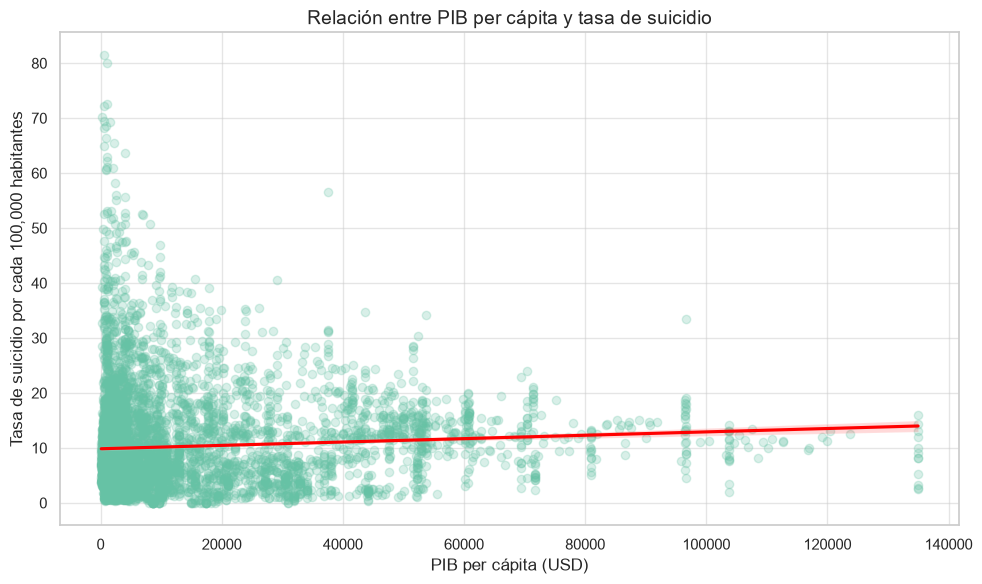

In [10]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_both,
    x="gdp_per_capita_usd",
    y="suicide_rate_per_100k",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"}
)

plt.title("Relación entre PIB per cápita y tasa de suicidio")
plt.xlabel("PIB per cápita (USD)")
plt.ylabel("Tasa de suicidio por cada 100,000 habitantes")

plt.tight_layout()
plt.show()

La línea de regresión muestra una pendiente ligeramente positiva entre el PIB per cápita y la tasa de suicidio. Sin embargo, la gran dispersión de las observaciones alrededor de la línea indica que esta asociación es muy débil.

En consecuencia, el gráfico no permite afirmar que un mayor PIB per cápita provoque una mayor tasa de suicidio. Únicamente evidencia una asociación lineal positiva muy débil en los datos analizados.

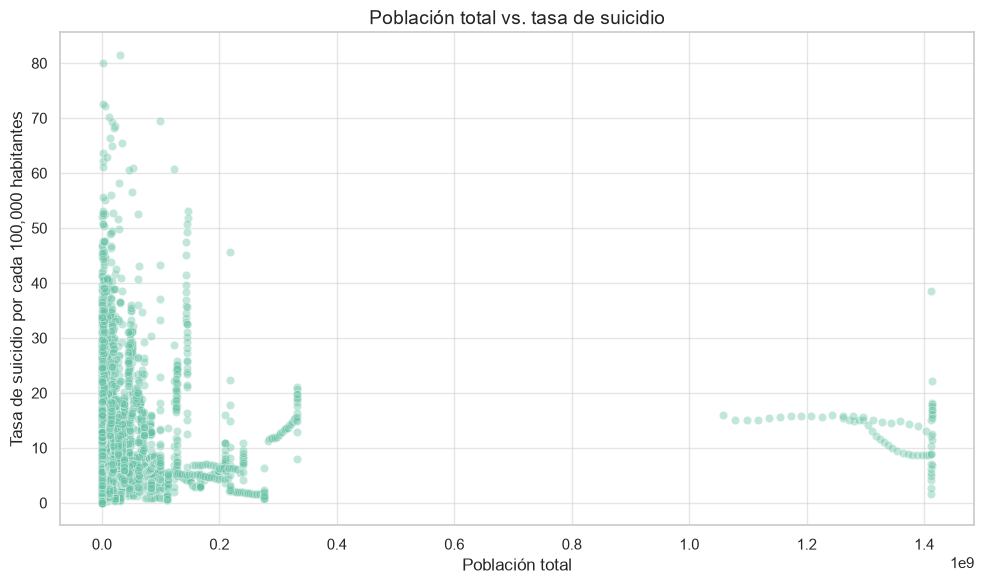

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_both,
    x="total_country_population",
    y="suicide_rate_per_100k",
    alpha=0.4
)

plt.title("Población total vs. tasa de suicidio")
plt.xlabel("Población total")
plt.ylabel("Tasa de suicidio por cada 100,000 habitantes")

plt.tight_layout()
plt.show()

El diagrama de dispersión muestra que no existe una relación lineal clara entre la población total de un país y la tasa de suicidio. Las observaciones correspondientes a poblaciones pequeñas y medianas presentan una gran dispersión, con tasas que van desde valores cercanos a cero hasta más de 80 suicidios por cada 100,000 habitantes.

También se observa que los valores extremos de la tasa de suicidio se concentran principalmente entre observaciones correspondientes a poblaciones relativamente menores. Sin embargo, esto no significa que una menor población provoque tasas de suicidio más elevadas, ya que la concentración de puntos también depende de la distribución de países, años y grupos de edad presentes en el conjunto de datos.

En los países con poblaciones muy grandes, superiores a aproximadamente 1,000 millones de habitantes, las tasas visibles se encuentran mayoritariamente alrededor de 9 a 16 por cada 100,000 habitantes, aunque también aparecen algunas observaciones fuera de ese rango.

Este comportamiento coincide con la matriz de correlación, donde la relación entre total_country_population y suicide_rate_per_100k fue de apenas 0.02, un valor prácticamente nulo. Por lo tanto, la población total por sí sola no presenta una asociación lineal relevante con la tasa de suicidio en los datos analizados.

## Evolución de países seleccionados

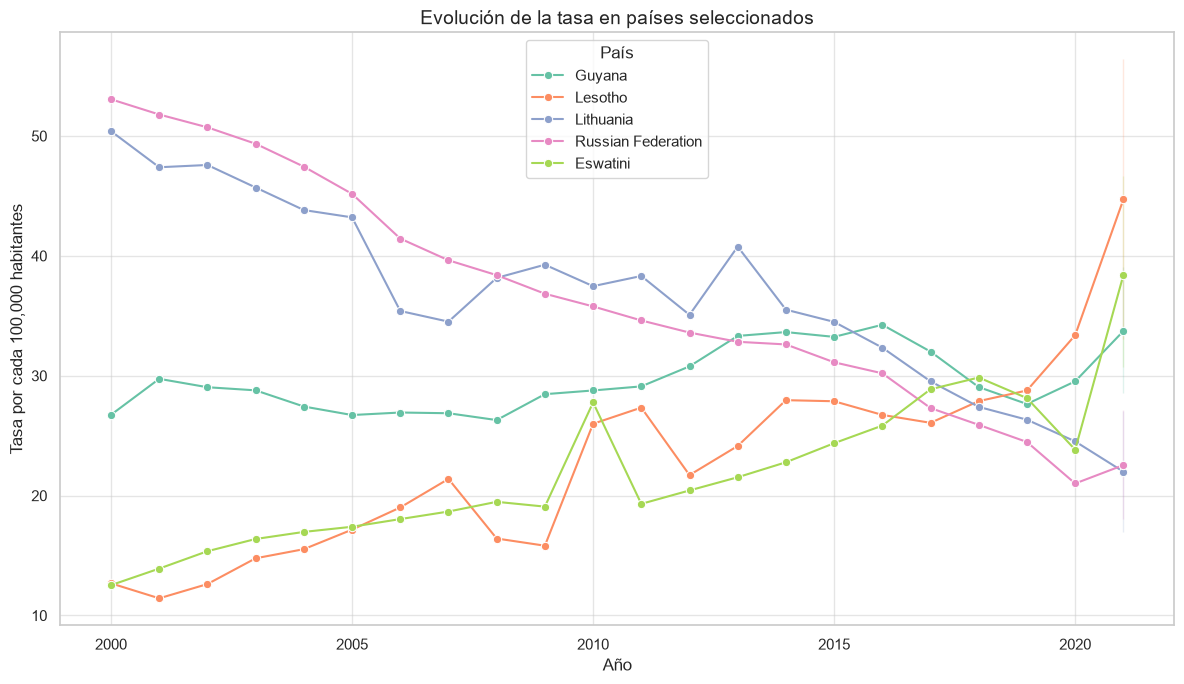

In [12]:
paises_top = (
    df_both.groupby("country")["suicide_rate_per_100k"]
    .mean()
    .nlargest(5)
    .index
)

df_top = df_both[df_both["country"].isin(paises_top)]

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=df_top,
    x="year",
    y="suicide_rate_per_100k",
    hue="country",
    marker="o"
)

plt.title("Evolución de la tasa en países seleccionados")
plt.xlabel("Año")
plt.ylabel("Tasa por cada 100,000 habitantes")

plt.legend(title="País")
plt.tight_layout()
plt.show()

Entre 2000 y 2021 se observan comportamientos temporales claramente diferentes en los cinco países seleccionados.

Russian Federation y Lithuania parten con las tasas más altas, alrededor de 53 y 50 suicidios por cada 100,000 habitantes, respectivamente. Sin embargo, ambos presentan una tendencia general descendente. Russian Federation disminuye de aproximadamente 53 en 2000 hasta cerca de 22 en 2021, mientras que Lithuania pasa de aproximadamente 50 a cerca de 23. Por lo tanto, sus posiciones elevadas en el ranking de promedios están influenciadas en parte por las altas tasas observadas durante los primeros años del período.

En contraste, Guyana mantiene un comportamiento relativamente más estable, generalmente entre aproximadamente 26 y 34, aunque con fluctuaciones. Lesotho y Eswatini muestran una trayectoria diferente, con valores inicialmente menores pero una tendencia general creciente y mayor variabilidad. En 2021 se observa un incremento particularmente marcado, con Lesotho alrededor de 45 y Eswatini cerca de 38 por cada 100,000 habitantes.

En conjunto, el gráfico demuestra que un promedio alto puede originarse en patrones temporales muy diferentes: algunos países presentan tasas históricamente altas que disminuyen con el tiempo, mientras que otros muestran incrementos más recientes. Por esta razón, el ranking basado únicamente en promedios debe complementarse con el análisis temporal para comprender adecuadamente la evolución de cada país.

## Tasa de suicidio por grupo de edad

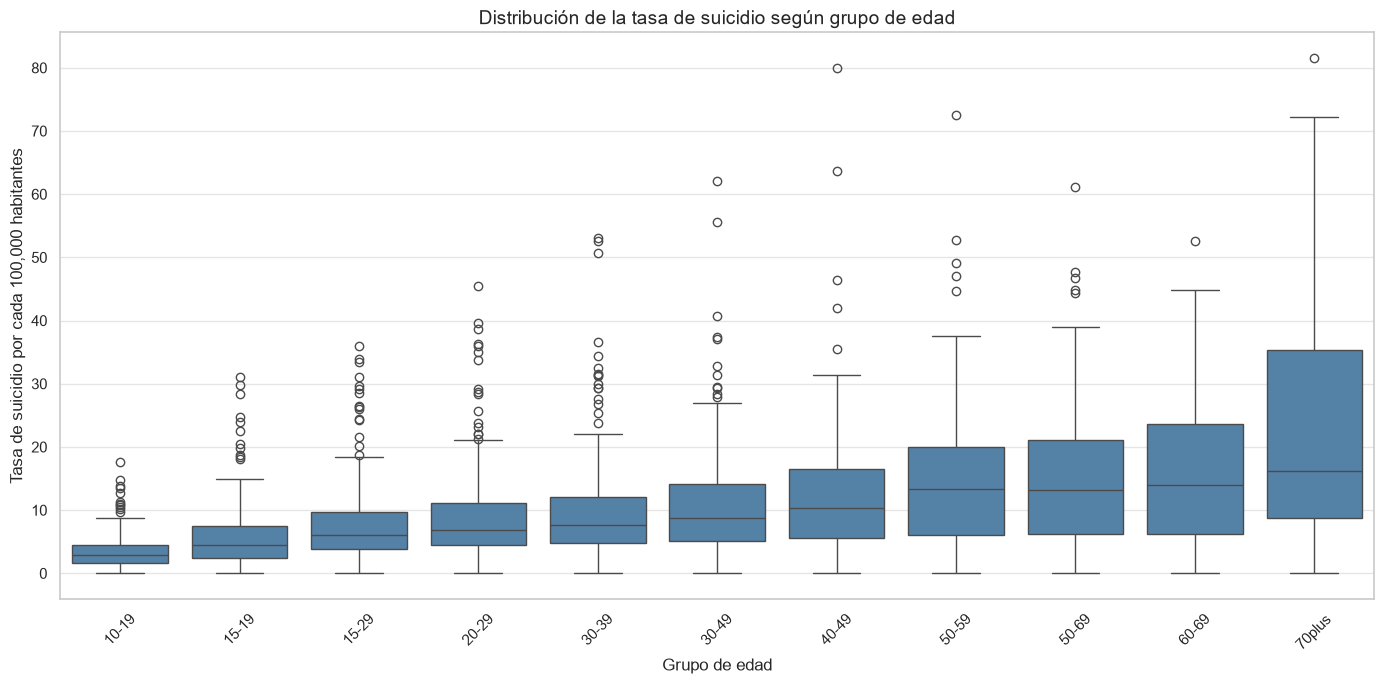

In [23]:
# Excluir all_ages para comparar únicamente grupos de edad
df_age = df_both[df_both["age_bracket"] != "all_ages"].copy()

orden_edades = [
    "10-19",
    "15-19",
    "15-29",
    "20-29",
    "30-39",
    "30-49",
    "40-49",
    "50-59",
    "50-69",
    "60-69",
    "70plus"
]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_age,
    x="age_bracket",
    y="suicide_rate_per_100k",
    order=orden_edades,
    color="steelblue"
)

plt.title("Distribución de la tasa de suicidio según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Tasa de suicidio por cada 100,000 habitantes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

El boxplot muestra diferencias claras en la distribución de la tasa de suicidio entre los distintos grupos de edad. En términos generales, se observa un incremento progresivo de la mediana conforme aumenta la edad. Los grupos más jóvenes, particularmente 10-19 y 15-19, presentan las tasas centrales más bajas, mientras que los grupos 50-59, 60-69 y especialmente 70plus muestran niveles considerablemente mayores.

También aumenta la dispersión de las observaciones en los grupos de mayor edad. El grupo 70plus presenta la distribución más amplia, con una mediana cercana a 16 por cada 100,000 habitantes, un rango intercuartílico aproximadamente entre 9 y 35, y observaciones que superan los 70 e incluso alcanzan valores cercanos a 80.

Los valores atípicos aparecen en prácticamente todos los grupos, pero son más elevados en edades medias y avanzadas. Por ejemplo, se observan valores extremos cercanos a 80 en 40-49 y superiores a 80 en 70plus.

En conjunto, la visualización evidencia una asociación entre el grupo de edad y la distribución de la tasa de suicidio, donde los grupos de mayor edad tienden a presentar tanto tasas centrales más elevadas como una mayor variabilidad.

## Media por grupo de edad y sexo

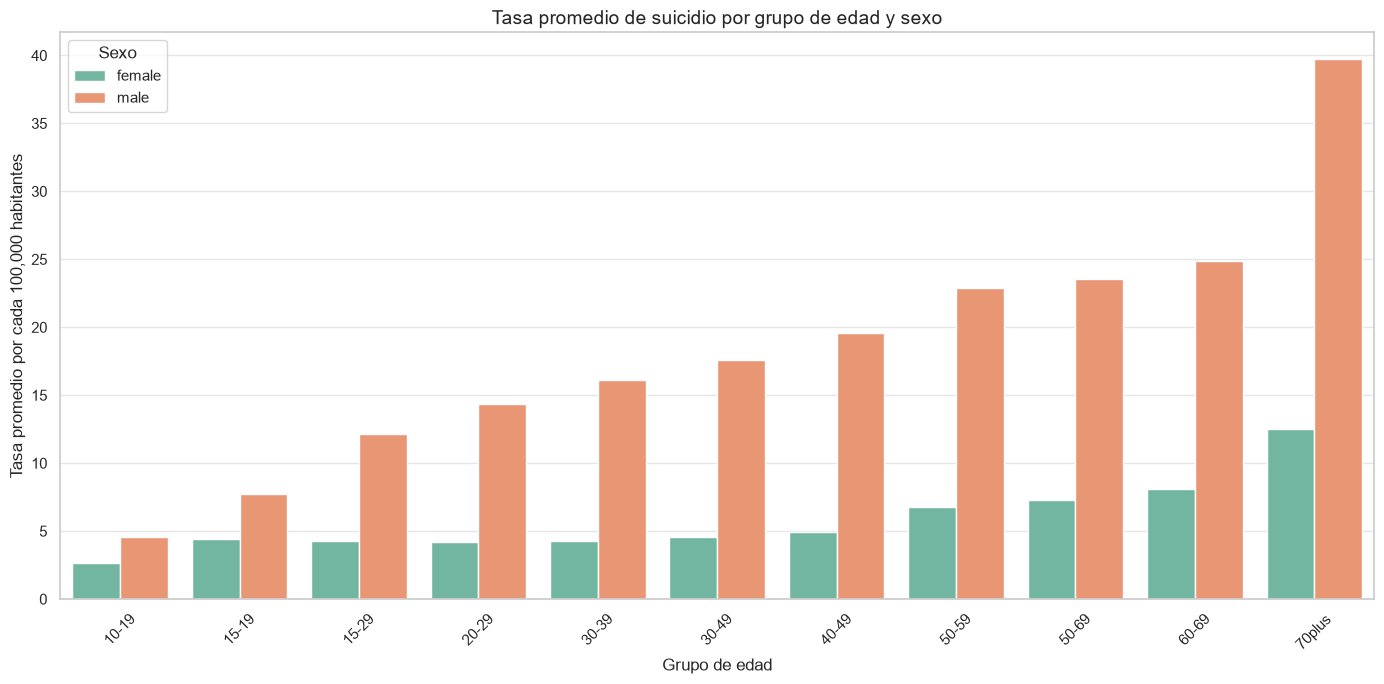

In [24]:
df_age_sex = df[
    (df["sex"].isin(["male", "female"])) &
    (df["age_bracket"] != "all_ages")
].copy()

resumen = (
    df_age_sex
    .groupby(["age_bracket", "sex"])["suicide_rate_per_100k"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=resumen,
    x="age_bracket",
    y="suicide_rate_per_100k",
    hue="sex",
    order=orden_edades
)

plt.title("Tasa promedio de suicidio por grupo de edad y sexo")
plt.xlabel("Grupo de edad")
plt.ylabel("Tasa promedio por cada 100,000 habitantes")
plt.xticks(rotation=45)
plt.legend(title="Sexo")

plt.tight_layout()
plt.show()

El gráfico muestra que las observaciones correspondientes a male presentan una tasa promedio de suicidio superior a female en todos los grupos de edad analizados. Sin embargo, la diferencia entre ambos grupos no permanece constante, sino que se amplía progresivamente en edades mayores.

En el grupo 10-19, los promedios son relativamente bajos y cercanos entre sí, aproximadamente 4.5 para male y 2.5 para female por cada 100,000 habitantes. A partir de los siguientes grupos, la tasa promedio masculina aumenta de manera mucho más pronunciada, superando aproximadamente 19 en 40-49, 23-25 entre 50-59 y 60-69, y alcanzando cerca de 40 por cada 100,000 habitantes en 70plus.

Las observaciones de female también presentan un aumento con la edad, pero de forma considerablemente más moderada. El valor promedio pasa de aproximadamente 2.5 en 10-19 a alrededor de 12 en 70plus.
El grupo 70plus presenta la mayor diferencia observada entre ambos sexos: aproximadamente 40 por cada 100,000 habitantes en male frente a 12 en female, es decir, una tasa promedio masculina superior a tres veces la femenina.

En conjunto, esta visualización sugiere que edad y sexo son dos características importantes para describir la variabilidad de la tasa de suicidio, y que la diferencia observada entre male y female es especialmente marcada en los grupos de mayor edad.

### Conclusiones del EDA Visual

El análisis visual permitió identificar patrones relevantes en la distribución y comportamiento de la tasa de suicidio, complementando los resultados obtenidos previamente mediante el análisis estadístico.

1. **Distribución y valores atípicos.** La tasa de suicidio presenta una distribución asimétrica hacia la derecha. La mayoría de las observaciones se concentra en valores bajos e intermedios, mientras que existe un grupo reducido con tasas considerablemente elevadas. Los histogramas y boxplots permitieron confirmar la presencia de numerosos valores atípicos superiores. Estos valores no se consideran automáticamente errores, ya que pueden corresponder a combinaciones reales de país, año y grupo de edad con tasas particularmente altas.
2. **Diferencias según sexo.** Se observan diferencias importantes entre las categorías male y female. Las observaciones correspondientes a male presentan una mediana mayor, una dispersión más amplia y valores extremos superiores. Por tanto, el sexo se encuentra asociado con diferencias importantes en la distribución de la tasa de suicidio dentro de los datos analizados.
3. **Comportamiento temporal.** Entre 2000 y 2020 se observa una tendencia general descendente de la tasa media, mientras que la mediana permanece relativamente más estable. La media se mantiene por encima de la mediana durante todo el período, comportamiento consistente con la asimetría positiva y los valores extremos detectados previamente. En 2021 se observa un incremento marcado de la media, mientras que el aumento de la mediana es considerablemente menor, lo que sugiere una influencia importante de observaciones con tasas elevadas durante ese año.
4. **Diferencias entre países.** El análisis por país muestra una importante heterogeneidad geográfica. Russian Federation y Lithuania presentan los promedios más elevados entre las observaciones analizadas, cercanos a 32 por cada 100,000 habitantes, seguidos por Guyana y Lesotho. Sin embargo, el análisis temporal demuestra que países con promedios similares pueden tener comportamientos muy diferentes. Russian Federation y Lithuania, por ejemplo, muestran una tendencia general descendente, mientras que Lesotho y Eswatini presentan incrementos más recientes.
5. **Variables económicas y demográficas.** No se identificaron relaciones lineales fuertes entre la tasa de suicidio y las variables económicas o demográficas analizadas. Las correlaciones de suicide\_rate\_per\_100k con gdp\_usd, gdp\_per\_capita\_usd y total\_country\_population fueron aproximadamente 0.07, 0.07 y 0.02, respectivamente. Los diagramas de dispersión respaldan este resultado al mostrar una elevada dispersión de las observaciones. Por lo tanto, variables como el PIB per cápita o la población total, consideradas individualmente, no permiten describir adecuadamente las variaciones de la tasa de suicidio.
6. **Importancia del grupo de edad.** Se observa un patrón general de incremento de las tasas conforme avanzan los grupos de edad, acompañado también por una mayor dispersión. Los grupos de mayor edad presentan niveles centrales superiores, destacándose especialmente 70plus. Esto indica que la edad constituye una característica relevante para comprender la heterogeneidad presente en las tasas observadas.
7. **Interacción visual entre edad y sexo.** La comparación conjunta evidencia que male presenta una tasa promedio superior a female en todos los grupos de edad analizados. Además, esta diferencia aumenta especialmente en edades avanzadas. En 70plus, la tasa promedio de male se aproxima a 40 por cada 100,000 habitantes, frente a aproximadamente 12 en female, constituyendo la diferencia más marcada entre ambos grupos.

### Conclusión general

En conjunto, el EDA visual evidencia que la tasa de suicidio presenta un comportamiento **heterogéneo y multidimensional**. Las diferencias más claras aparecen asociadas con el sexo, el grupo de edad, el país y la evolución temporal, mientras que las variables económicas y demográficas analizadas presentan relaciones lineales considerablemente más débiles con la tasa.

Los resultados también demuestran la importancia de complementar las medidas agregadas con diferentes perspectivas visuales. Un promedio por país, por ejemplo, puede ocultar tendencias temporales muy distintas, mientras que una media general puede verse afectada considerablemente por observaciones extremas.

Estos hallazgos proporcionan una base exploratoria para la siguiente etapa del proyecto, en la cual se aplicará **clusterización mediante K\-medias** con el objetivo de identificar grupos de observaciones con características similares. La selección y preparación de las variables para la clusterización deberá considerar las diferencias de escala, la presencia de valores atípicos y los patrones identificados durante este análisis exploratorio.

